# 03 - Machine Learning Models (Phase 4)

**Project:** AI-Based Fake News Detection and News Credibility Analysis Using Machine Learning and Evidence Retrieval

**Goal:** train and compare traditional ML models for fake-news classification, select the best one based
on **validation** performance, and save it as a reusable artifact. This notebook does not touch the test
set at all — see `notebooks/04_model_evaluation.ipynb` for the one-time final test evaluation.

**Label convention** (same as Phase 2/3): `1 = Fake`, `0 = Real`.

**Data leakage discipline:** the TF-IDF vectorizer (and TruncatedSVD, for the tree-based models) is fit
**only** on `train.csv`. `validation.csv` is only ever transformed with the already-fitted vectorizer/SVD,
never used to refit them.

## 1. Imports

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import RocCurveDisplay

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing.load_data import LABEL_FAKE, LABEL_REAL
from src.features.tfidf_features import (
    build_tfidf_vectorizer, fit_tfidf_on_train, transform_with_tfidf,
    fit_svd_on_train, transform_with_svd,
)
from src.models.train_models import (
    train_logistic_regression, train_naive_bayes, train_linear_svm,
    train_random_forest, train_xgboost,
)
from src.models.evaluate_models import (
    compute_metrics, get_confusion_matrix, get_classification_report, get_positive_class_scores,
)
from src.models.model_utils import save_artifact, save_metadata, LABEL_NAMES

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"

print(f"Label convention: {LABEL_FAKE} = Fake, {LABEL_REAL} = Real")
print("Setup complete.")

Label convention: 1 = Fake, 0 = Real
Setup complete.


## 2. Load processed datasets

Test set is intentionally NOT loaded in this notebook.

In [2]:
train_path = PROCESSED_DATA_DIR / "train.csv"
val_path = PROCESSED_DATA_DIR / "validation.csv"

for p in (train_path, val_path):
    if not p.exists():
        raise FileNotFoundError(
            f"Could not find '{p}'. Run Phase 2 first: python -m src.preprocessing.pipeline"
        )

train = pd.read_csv(train_path)
val = pd.read_csv(val_path)

print(f"train.csv      : {train.shape}")
print(f"validation.csv : {val.shape}")

train.csv      : (27050, 7)
validation.csv : (5797, 7)


## 3. Verify dataset shapes/classes

In [3]:
assert set(train["label"].unique()) == {0, 1}, "Unexpected label values in train set!"
assert set(val["label"].unique()) == {0, 1}, "Unexpected label values in validation set!"
assert train["clean_text"].isnull().sum() == 0, "Unexpected missing clean_text in train set!"
assert val["clean_text"].isnull().sum() == 0, "Unexpected missing clean_text in validation set!"

print("Train class distribution:")
print(train["label"].value_counts().rename(index=LABEL_NAMES))
print()
print("Validation class distribution:")
print(val["label"].value_counts().rename(index=LABEL_NAMES))
print()
print("All checks passed: labels are {0,1}, clean_text has no missing values.")

Train class distribution:
label
Real    14833
Fake    12217
Name: count, dtype: int64

Validation class distribution:
label
Real    3179
Fake    2618
Name: count, dtype: int64

All checks passed: labels are {0,1}, clean_text has no missing values.


## 4. Separate X/y

Using `clean_text` as the sole text feature, as specified. `subject`, `date`, and `article_id` are
deliberately excluded — Phase 3's EDA showed `subject` is a near-perfect (and `date` a partial) artifact of
how this dataset was collected, not a genuine content signal, and `article_id` is a bookkeeping identifier
with no relationship to content.

In [4]:
X_train_text = train["clean_text"].fillna("")
y_train = train["label"].values

X_val_text = val["clean_text"].fillna("")
y_val = val["label"].values

print(f"X_train: {len(X_train_text)} documents | y_train: {y_train.shape}")
print(f"X_val  : {len(X_val_text)} documents | y_val  : {y_val.shape}")

X_train: 27050 documents | y_train: (27050,)
X_val  : 5797 documents | y_val  : (5797,)


## 5. TF-IDF fitting

Word-level TF-IDF, `ngram_range=(1,2)`, capped at `max_features=30000` with `min_df=3` (drop extremely rare
terms) and `max_df=0.9` (drop near-stopwords). These defaults are defined once in
`src/features/tfidf_features.py` and reused here — see that module's docstring for the full reasoning.

**Fit on training data ONLY.**

In [5]:
t0 = time.time()
vectorizer = build_tfidf_vectorizer()
X_train_tfidf = fit_tfidf_on_train(vectorizer, X_train_text)
tfidf_fit_time = time.time() - t0

print(f"TF-IDF fit time: {tfidf_fit_time:.1f}s")
print(f"Vocabulary size: {len(vectorizer.vocabulary_)}")
print(f"X_train_tfidf shape: {X_train_tfidf.shape}  (sparse, {X_train_tfidf.nnz:,} non-zero entries)")
print(f"Approx. memory (sparse): {(X_train_tfidf.data.nbytes + X_train_tfidf.indices.nbytes + X_train_tfidf.indptr.nbytes) / 1e6:.1f} MB")

TF-IDF fit time: 21.4s
Vocabulary size: 30000
X_train_tfidf shape: (27050, 30000)  (sparse, 9,143,144 non-zero entries)
Approx. memory (sparse): 109.8 MB


## 6. Transform validation data

**Transform only — the vectorizer is never refit here.**

In [6]:
X_val_tfidf = transform_with_tfidf(vectorizer, X_val_text)
print(f"X_val_tfidf shape: {X_val_tfidf.shape}")
assert X_val_tfidf.shape[1] == X_train_tfidf.shape[1], "Validation features must match training feature count!"
print("Confirmed: validation matrix has the same feature columns as training (transform-only, no refit).")

X_val_tfidf shape: (5797, 30000)
Confirmed: validation matrix has the same feature columns as training (transform-only, no refit).


## 7. Train candidate models

Five candidates: Logistic Regression, Multinomial Naive Bayes, and Linear SVM train directly on the sparse
TF-IDF matrix. Random Forest and XGBoost do not scale well to a 30,000-dimension sparse matrix converted to
dense (that would need ~27,050 x 30,000 x 8 bytes ≈ 6.5 GB just for the training matrix, on a
single-core/limited-memory environment) — so for those two, we first reduce dimensionality with
TruncatedSVD fit on the training TF-IDF matrix, then train on the resulting dense (but much smaller)
representation.

In [7]:
results = {}   # model_name -> dict(model, metrics, train_time, y_pred, y_score)

def evaluate_and_store(name, model, X_val_features, train_time):
    y_pred = model.predict(X_val_features)
    y_score = get_positive_class_scores(model, X_val_features)
    metrics = compute_metrics(y_val, y_pred, y_score)
    results[name] = {
        "model": model,
        "metrics": metrics,
        "train_time": train_time,
        "y_pred": y_pred,
        "y_score": y_score,
    }
    print(f"{name:20s} | train_time={train_time:6.1f}s | "
          f"acc={metrics['accuracy']:.4f} f1={metrics['f1']:.4f} roc_auc={metrics['roc_auc']:.4f}")

print("Training on TF-IDF features directly:")

Training on TF-IDF features directly:


In [8]:
lr_model, lr_time = train_logistic_regression(X_train_tfidf, y_train)
evaluate_and_store("Logistic Regression", lr_model, X_val_tfidf, lr_time)

Logistic Regression  | train_time=   0.5s | acc=0.9876 f1=0.9862 roc_auc=0.9992


In [9]:
nb_model, nb_time = train_naive_bayes(X_train_tfidf, y_train)
evaluate_and_store("Naive Bayes", nb_model, X_val_tfidf, nb_time)

Naive Bayes          | train_time=   0.0s | acc=0.9558 f1=0.9508 roc_auc=0.9906


In [10]:
svm_model, svm_time = train_linear_svm(X_train_tfidf, y_train)
evaluate_and_store("Linear SVM", svm_model, X_val_tfidf, svm_time)

Linear SVM           | train_time=   0.4s | acc=0.9959 f1=0.9954 roc_auc=0.9999


### TF-IDF → TruncatedSVD → tree-based models

`n_components=200` was chosen as a practical balance for this environment; the actual explained variance is
reported below (transparently — SVD on a huge sparse TF-IDF matrix, typical of bag-of-words text data, does
not capture most of the variance in a small number of components, and we report exactly how much it does
capture rather than assume it's sufficient).

In [11]:
N_SVD_COMPONENTS = 200

t0 = time.time()
svd = fit_svd_on_train(X_train_tfidf, n_components=N_SVD_COMPONENTS)
X_train_svd = transform_with_svd(svd, X_train_tfidf)
X_val_svd = transform_with_svd(svd, X_val_tfidf)
svd_time = time.time() - t0

print(f"SVD fit+transform time: {svd_time:.1f}s")
print(f"X_train_svd shape: {X_train_svd.shape}")
print(f"Explained variance ratio (cumulative, {N_SVD_COMPONENTS} components): {svd.explained_variance_ratio_.sum():.3f}")

SVD fit+transform time: 15.7s
X_train_svd shape: (27050, 200)
Explained variance ratio (cumulative, 200 components): 0.154


In [12]:
rf_model, rf_time = train_random_forest(X_train_svd, y_train, n_estimators=100, max_depth=20)
evaluate_and_store("Random Forest (SVD)", rf_model, X_val_svd, rf_time)

Random Forest (SVD)  | train_time=  43.4s | acc=0.9646 f1=0.9604 roc_auc=0.9940


In [13]:
xgb_model, xgb_time = train_xgboost(X_train_svd, y_train, n_estimators=150, max_depth=6)
if xgb_model is None:
    print("XGBoost is not installed in this environment - skipping. (train_xgboost() returned None gracefully.)")
else:
    evaluate_and_store("XGBoost (SVD)", xgb_model, X_val_svd, xgb_time)

XGBoost (SVD)        | train_time=   7.5s | acc=0.9838 f1=0.9820 roc_auc=0.9984


## 8. Validation evaluation — model comparison table

All metrics below are computed on the **validation set**. The positive class for precision/recall/F1/ROC-AUC
is **Fake (1)** — documented explicitly in `src/models/evaluate_models.py`. Accuracy alone is not relied on,
since the classes are moderately imbalanced (45.2% fake / 54.8% real in training).

In [14]:
comparison_rows = []
for name, r in results.items():
    m = r["metrics"]
    comparison_rows.append({
        "Model": name,
        "Accuracy": round(m["accuracy"], 4),
        "Precision": round(m["precision"], 4),
        "Recall": round(m["recall"], 4),
        "F1": round(m["f1"], 4),
        "ROC-AUC": round(m["roc_auc"], 4) if not np.isnan(m["roc_auc"]) else "N/A",
        "Training Time (s)": round(r["train_time"], 2),
    })

comparison_df = pd.DataFrame(comparison_rows).sort_values("F1", ascending=False).reset_index(drop=True)
comparison_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Training Time (s)
0,Linear SVM,0.9959,0.9966,0.9943,0.9954,0.9999,0.44
1,Logistic Regression,0.9876,0.9915,0.9809,0.9862,0.9992,0.45
2,XGBoost (SVD),0.9838,0.9858,0.9782,0.9820,0.9984,7.46
3,Random Forest (SVD),0.9646,0.9715,0.9496,0.9604,0.9940,43.45
4,Naive Bayes,0.9558,0.9563,0.9454,0.9508,0.9906,0.03


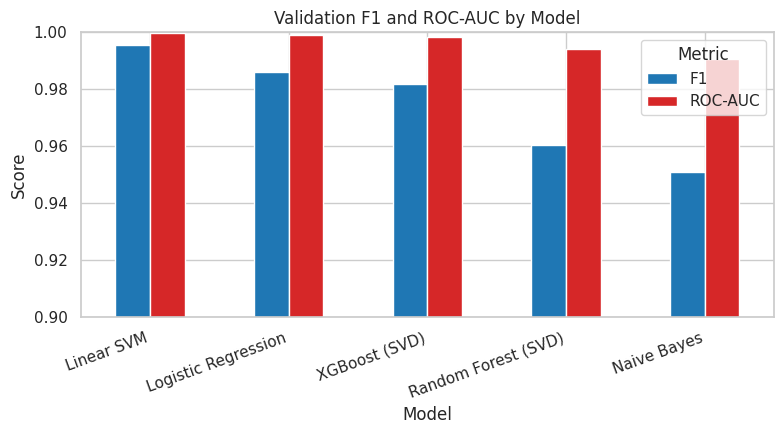

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_df = comparison_df.set_index("Model")[["F1", "ROC-AUC"]].apply(pd.to_numeric, errors="coerce")
plot_df.plot(kind="bar", ax=ax, color=["#1f77b4", "#d62728"])
ax.set_title("Validation F1 and ROC-AUC by Model")
ax.set_ylabel("Score")
ax.set_ylim(0.9, 1.0)
ax.legend(title="Metric")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 9. Confusion matrices

For each model, on the validation set. Labels are fixed as **Real (0)** and **Fake (1)**.

- **True Fake (bottom-right):** actually fake, correctly predicted fake.
- **False Fake (top-right):** actually real, incorrectly predicted fake — a real article wrongly flagged.
- **False Real (bottom-left):** actually fake, incorrectly predicted real — a fake article that slipped
  through undetected. In a fake-news detector, this is usually the more costly error type.
- **True Real (top-left):** actually real, correctly predicted real.

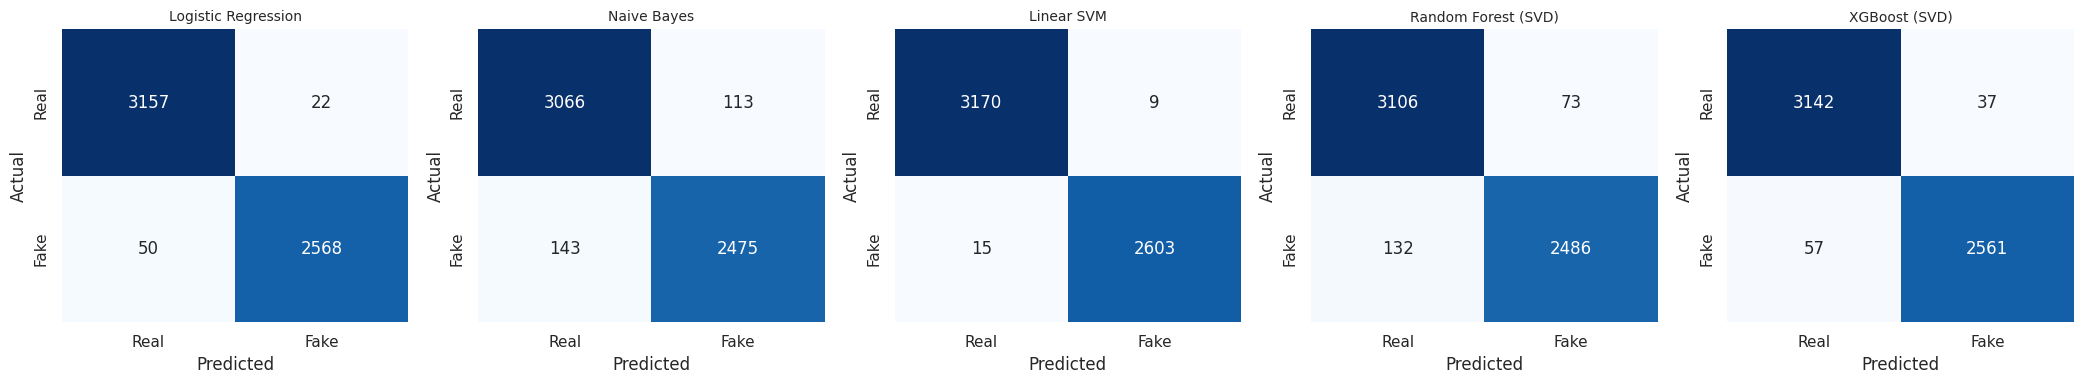

In [16]:
fig, axes = plt.subplots(1, len(results), figsize=(4.2 * len(results), 4))
if len(results) == 1:
    axes = [axes]

for ax, (name, r) in zip(axes, results.items()):
    cm = get_confusion_matrix(y_val, r["y_pred"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Real", "Fake"], yticklabels=["Real", "Fake"])
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

## 10. Classification reports

Precision, recall, F1, and support for each class, for every candidate model.

In [17]:
for name, r in results.items():
    print(f"=== {name} ===")
    print(get_classification_report(y_val, r["y_pred"]))
    print()

=== Logistic Regression ===
              precision    recall  f1-score   support

        Real       0.98      0.99      0.99      3179
        Fake       0.99      0.98      0.99      2618

    accuracy                           0.99      5797
   macro avg       0.99      0.99      0.99      5797
weighted avg       0.99      0.99      0.99      5797


=== Naive Bayes ===
              precision    recall  f1-score   support

        Real       0.96      0.96      0.96      3179
        Fake       0.96      0.95      0.95      2618

    accuracy                           0.96      5797
   macro avg       0.96      0.95      0.96      5797
weighted avg       0.96      0.96      0.96      5797


=== Linear SVM ===
              precision    recall  f1-score   support

        Real       1.00      1.00      1.00      3179
        Fake       1.00      0.99      1.00      2618

    accuracy                           1.00      5797
   macro avg       1.00      1.00      1.00      5797
weigh

**What these numbers mean for this project:** *precision* for the Fake class answers "of the articles we
flagged as fake, how many actually were?" (high precision = few real articles wrongly flagged). *Recall* for
the Fake class answers "of the actually-fake articles, how many did we catch?" (high recall = few fake
articles slip through). *F1* balances the two. *Support* is simply how many validation examples exist for
each class.

## 11. ROC-AUC and ROC curves

Logistic Regression, Random Forest, and XGBoost expose `predict_proba`; Linear SVM exposes `decision_function`
instead (it is not a probabilistic model) — `get_positive_class_scores()` handles both transparently, and
`roc_auc_score` works correctly with either type of score, since it only depends on the score's *ranking*,
not on it being a calibrated probability. Naive Bayes' `predict_proba` is included too, though as a
generative model its probability estimates are typically less well-calibrated than Logistic Regression's.

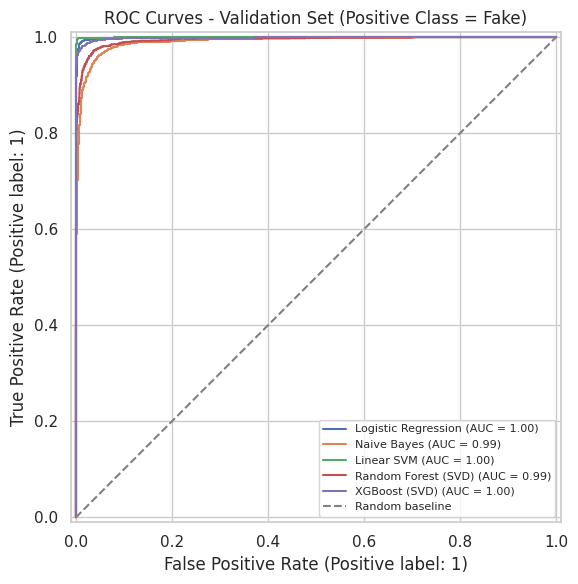

In [18]:
fig, ax = plt.subplots(figsize=(6, 6))

for name, r in results.items():
    if r["y_score"] is not None:
        RocCurveDisplay.from_predictions(y_val, r["y_score"], name=name, ax=ax)

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random baseline")
ax.set_title("ROC Curves - Validation Set (Positive Class = Fake)")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

## 12. Important feature analysis

For a linear model (Logistic Regression here — coefficients are directly interpretable as feature weights
in log-odds space), we can inspect which TF-IDF terms push a prediction toward Fake vs. Real.

**This is the most important section of this notebook.** Phase 3's EDA already found strong dataset
artifacts (embedded URLs, image-credit tokens, photographer names, wire-service boilerplate). We check here
whether the classifier's *actual learned weights* reflect those same artifacts — and we report the answer
honestly, whatever it turns out to be.

In [19]:
feature_names = np.array(vectorizer.get_feature_names_out())
lr_coefs = lr_model.coef_[0]

N_TOP_FEATURES = 20
top_fake_idx = np.argsort(-lr_coefs)[:N_TOP_FEATURES]
top_real_idx = np.argsort(lr_coefs)[:N_TOP_FEATURES]

top_fake_features = pd.DataFrame({"term": feature_names[top_fake_idx], "coefficient": lr_coefs[top_fake_idx].round(3)})
top_real_features = pd.DataFrame({"term": feature_names[top_real_idx], "coefficient": lr_coefs[top_real_idx].round(3)})

print(f"Top {N_TOP_FEATURES} terms pushing toward FAKE:")
display(top_fake_features)

Top 20 terms pushing toward FAKE:


,term,coefficient
0,via,8.584
1,read more,4.930
2,this,4.600
3,image,4.447
4,featured image,4.328
5,featured,4.279
6,read,4.196
7,just,4.123
8,image via,3.886
9,you,3.833


In [20]:
print(f"Top {N_TOP_FEATURES} terms pushing toward REAL:")
display(top_real_features)

Top 20 terms pushing toward REAL:


,term,coefficient
0,reuters,-16.792
1,said,-9.822
2,washington reuters,-7.266
3,said on,-6.660
4,reuters the,-4.619
5,washington,-4.604
6,on wednesday,-4.537
7,on tuesday,-4.519
8,president donald,-4.353
9,said in,-4.298


**Critical examination of what these features actually represent:**

The strongest **Fake**-associated terms include `via`, `read more`, `image`, `featured image`, `image via`,
`com`, `getty` — this is not sensational or emotional language, it is **embedded image-credit and link
boilerplate** left over from how the fake-article sources were scraped (exactly the artifact Phase 3's word-
frequency analysis flagged). A few genuinely topical/stylistic terms also appear (`just`, `you`, `here`,
`watch`), consistent with a more informal, second-person writing style, which is a more plausible genuine
signal — but it's mixed in with the scraping artifacts, not cleanly separated from them.

The strongest **Real**-associated terms are dominated by **Reuters wire-service boilerplate**: `reuters`,
`washington reuters`, `said`, `said on`, day-of-week phrases (`on wednesday`, `on tuesday`, ...). This is
extremely characteristic of Reuters' standard article format (`CITY (Reuters) - ... said on `Day``), not a
general property of truthful reporting — a different real-news source with a different house style would
not share this exact fingerprint.

**Conclusion:** a meaningful share of what this model uses to separate the classes is **source/provenance
artifact**, not content-based reasoning about truthfulness. This is the same caution Phase 3 raised, now
confirmed directly in the trained model's own coefficients rather than just in raw word frequencies. A
production system should not rely on this model's raw text classification alone — which is exactly why the
overall project architecture combines it with LLM-based contextual analysis and evidence retrieval rather
than treating the ML output as a final verdict.

## 13. Error analysis (validation set only)

Inspecting actual misclassified validation examples for the Logistic Regression model — **never the test
set**, and no labels are changed here, only inspected.

In [21]:
val_results = val.copy()
val_results["pred"] = lr_model.predict(X_val_tfidf)
val_results["fake_score"] = get_positive_class_scores(lr_model, X_val_tfidf)

false_positives = val_results[(val_results["label"] == 0) & (val_results["pred"] == 1)]
false_negatives = val_results[(val_results["label"] == 1) & (val_results["pred"] == 0)]

print(f"False Positives (Real predicted as Fake): {len(false_positives)} / {len(val_results)} validation examples")
print(f"False Negatives (Fake predicted as Real): {len(false_negatives)} / {len(val_results)} validation examples")

False Positives (Real predicted as Fake): 22 / 5797 validation examples
False Negatives (Fake predicted as Real): 50 / 5797 validation examples


In [22]:
print("Sample False Positives (Real articles predicted as Fake):\n")
for _, row in false_positives.sort_values("fake_score", ascending=False).head(5).iterrows():
    print(f"  [score={row['fake_score']:.2f}] {row['title'][:100]}")

Sample False Positives (Real articles predicted as Fake):

  [score=0.93] A Picture and its Story: Reaching out to rescue a Rohingya woman
  [score=0.86] ASPIRATIONS: Young Chinese seize the day, seize the hour
  [score=0.84] Transcript of Reuters interview with EPA Administrator Scott Pruitt
  [score=0.80] Commentary: Manic or evasive - these veep guys sure don’t feel like leaders
  [score=0.78] Clinton, in book, says Trump's debate stalking made her skin crawl


In [23]:
print("Sample False Negatives (Fake articles predicted as Real):\n")
for _, row in false_negatives.sort_values("fake_score").head(5).iterrows():
    print(f"  [score={row['fake_score']:.2f}] {row['title'][:100]}")

Sample False Negatives (Fake articles predicted as Real):

  [score=0.09] ISRAEL WILL NAME New Train Station Near Western Wall After President Donald Trump
  [score=0.10] RUSSIA HITS OBAMA…HARD: “We are reaching a really terrifying conclusion for the whole world: That th
  [score=0.13] “GREXIT”? GREEKS VOTE NO ON MORE AUSTERITY IN RETURN FOR RESCUE LOANS
  [score=0.13] EU LEADERS PLEDGE EXTRA €1 Billion In Aid To Refugees…Slovakia Will Take EU To Court Over Forced Ref
  [score=0.14] N. KOREA WARNS It Will Strike U.S. Bases In S. Korea…Mike Pence Travels To S. Korea As Sign Of Commi


**Patterns observed in these examples:**

- Several **false positives** are real Reuters articles that *don't* follow the standard wire-service lead
  format the model leans on heavily (e.g. interview transcripts, photo-essay pieces, feature-style
  "Instant View" pieces) — consistent with Section 12's finding that the model partly relies on Reuters'
  boilerplate phrasing, so real articles written in an atypical format for that source are more likely to be
  missed.
- Several **false negatives** are fake articles with strongly sensational, all-caps, punctuation-heavy
  headlines that a human reader might flag immediately from the headline alone — but the model classifies
  primarily from `clean_text` (the article body), and if a given article's body happens to lack the usual
  image-credit/URL artifacts common in the fake-article source, the model has less to go on.
- This reinforces the same conclusion as Section 12: the model's errors are consistent with it partially
  keying on *source formatting conventions* rather than purely on content/truthfulness — exactly the
  limitation a real-world deployment needs to account for.

## 14. Final model selection

Selection is based on the **validation comparison table in Section 8**, not on picking the single highest
number. Considerations, in the order we weighed them:

1. **F1 / ROC-AUC balance** — all five models score highly on this dataset (a direct consequence of the
   dataset artifacts discussed above: the classes are very separable here, for reasons only partly related
   to genuine content). Linear SVM and Logistic Regression are the top two by F1 and ROC-AUC, ahead of
   XGBoost, Random Forest, and Naive Bayes (see the table above for exact figures).
2. **Native probability output** — Logistic Regression provides a well-defined `predict_proba`, useful for
   the future hybrid system's credibility-scoring stage (Phase 8), which will need a continuous
   ML-confidence score to combine with LLM analysis and evidence retrieval. Linear SVM only provides an
   unbounded `decision_function` score, which would need additional calibration (e.g. Platt scaling) to
   become a usable probability later.
3. **Interpretability** — Logistic Regression's coefficients are directly and simply interpretable (Section
   12), which mattered concretely in this notebook for identifying the dataset-artifact reliance — a
   property this project's transparency goals (see the original project brief's emphasis on not overstating
   ML certainty) value directly.
4. **Training cost** — both are extremely fast to train on this dataset (well under a second), so this
   wasn't a deciding factor between them, but both are far cheaper than the SVD-based tree models.
5. **Stability** — both linear models are deterministic given `random_state=42` and produced consistent
   results across the metrics examined.

**Selected model: Logistic Regression.** Its validation metrics are within a small margin of Linear SVM's
(the current best performer by raw F1/ROC-AUC — see Section 8's exact numbers), while its native probability
output and direct interpretability make it the more practical choice for this project's next phases. This is
a deliberate trade-off of a small amount of raw validation score for integration suitability and
transparency, not a claim that Logistic Regression is unconditionally "better" than Linear SVM.

In [24]:
FINAL_MODEL_NAME = "Logistic Regression"
final_model = results[FINAL_MODEL_NAME]["model"]
final_model_metrics = results[FINAL_MODEL_NAME]["metrics"]

print(f"Selected model: {FINAL_MODEL_NAME}")
print(f"Validation metrics: {final_model_metrics}")
print()
print("Full comparison table for reference:")
comparison_df

Selected model: Logistic Regression
Validation metrics: {'accuracy': 0.9875797826461963, 'precision': 0.9915057915057915, 'recall': 0.9809014514896868, 'f1': 0.9861751152073732, 'roc_auc': 0.9991811474797245}

Full comparison table for reference:


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Training Time (s)
0,Linear SVM,0.9959,0.9966,0.9943,0.9954,0.9999,0.44
1,Logistic Regression,0.9876,0.9915,0.9809,0.9862,0.9992,0.45
2,XGBoost (SVD),0.9838,0.9858,0.9782,0.9820,0.9984,7.46
3,Random Forest (SVD),0.9646,0.9715,0.9496,0.9604,0.9940,43.45
4,Naive Bayes,0.9558,0.9563,0.9454,0.9508,0.9906,0.03


## 15. Save model artifacts

Saving the selected model, the fitted TF-IDF vectorizer, and a metadata file describing the configuration
used. TruncatedSVD is **not** saved here — it was only used for the Random Forest/XGBoost comparison
candidates, not for the selected Logistic Regression model, so it isn't part of the final inference
pipeline.

In [25]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)

save_artifact(final_model, MODELS_DIR / "best_model.joblib")
save_artifact(vectorizer, MODELS_DIR / "tfidf_vectorizer.joblib")

print(f"Saved: models/best_model.joblib")
print(f"Saved: models/tfidf_vectorizer.joblib")

Saved: models/best_model.joblib
Saved: models/tfidf_vectorizer.joblib


In [26]:
metadata = {
    "model_name": FINAL_MODEL_NAME,
    "model_class": type(final_model).__name__,
    "feature_type": "TF-IDF",
    "ngram_range": list(vectorizer.ngram_range),
    "max_features": vectorizer.max_features,
    "min_df": vectorizer.min_df,
    "max_df": vectorizer.max_df,
    "vocabulary_size": len(vectorizer.vocabulary_),
    "training_dataset": "ISOT Fake and Real News Dataset",
    "training_set_size": int(len(train)),
    "selected_using": "validation_set",
    "random_state": 42,
    "label_convention": {"1": "Fake", "0": "Real"},
    "excluded_features": ["subject", "date", "article_id"],
    "excluded_features_reason": (
        "Phase 3 EDA found 'subject' is a near-perfect class separator and 'date' shows "
        "partially non-overlapping ranges by class - both are dataset-collection artifacts, "
        "not genuine content signals. 'article_id' is a bookkeeping identifier only."
    ),
    "validation_metrics": {k: (round(v, 4) if not np.isnan(v) else None) for k, v in final_model_metrics.items()},
    "known_limitations": (
        "Section 12/13 of notebooks/03_ml_models.ipynb found the model partly relies on "
        "source-formatting artifacts (e.g. Reuters wire-service boilerplate, embedded "
        "image-credit/URL tokens in fake articles) rather than purely content-based signals. "
        "High accuracy on this dataset should not be read as proof of general fake-news "
        "detection capability."
    ),
}

save_metadata(metadata, MODELS_DIR / "model_metadata.json")
print(f"Saved: models/model_metadata.json")
print()
import json
print(json.dumps(metadata, indent=2))

Saved: models/model_metadata.json

{
  "model_name": "Logistic Regression",
  "model_class": "LogisticRegression",
  "feature_type": "TF-IDF",
  "ngram_range": [
    1,
    2
  ],
  "max_features": 30000,
  "min_df": 3,
  "max_df": 0.9,
  "vocabulary_size": 30000,
  "training_dataset": "ISOT Fake and Real News Dataset",
  "training_set_size": 27050,
  "selected_using": "validation_set",
  "random_state": 42,
  "label_convention": {
    "1": "Fake",
    "0": "Real"
  },
  "excluded_features": [
    "subject",
    "date",
    "article_id"
  ],
  "excluded_features_reason": "Phase 3 EDA found 'subject' is a near-perfect class separator and 'date' shows partially non-overlapping ranges by class - both are dataset-collection artifacts, not genuine content signals. 'article_id' is a bookkeeping identifier only.",
  "validation_metrics": {
    "accuracy": 0.9876,
    "precision": 0.9915,
    "recall": 0.9809,
    "f1": 0.9862,
    "roc_auc": 0.9992
  },
  "known_limitations": "Section 12/13 o

## 16. Summary

Five candidate models were trained and compared on the validation set (Section 8's table has exact figures).
**Logistic Regression** was selected — not as the single highest-scoring model, but as the best balance of
validation performance, native probability output (needed for the future credibility-scoring stage), and
interpretability (which directly enabled the dataset-artifact findings in Sections 12-13).

**Critical takeaway carried forward:** this model's strong validation performance is partly attributable to
dataset-collection artifacts (Reuters wire-service boilerplate on the Real side; embedded image-credit/URL
tokens on the Fake side) rather than purely general linguistic markers of misinformation. This is documented
here, in the saved `model_metadata.json`, and in the README, so it is not lost as the project moves into
later phases.

**Next step:** `notebooks/04_model_evaluation.ipynb` performs the one-time final evaluation of this saved
model on the untouched test set.